Define Paths

In [ ]:
from pathlib import Path


def find_project_root(start=None):
    """Find the repository root by locating environment.yml and .git."""

    path = Path(start or Path.cwd()).resolve()

    for parent in [path, *path.parents]:
        if (
            (parent / "environment.yml").exists()
            and (parent / ".git").exists()
        ):
            return parent

    raise FileNotFoundError(
        "Could not find the project root."
    )


PROJECT_ROOT = find_project_root()

ADATA_DIR = PROJECT_ROOT / "Adata_Saves"
DATAFRAME_DIR = PROJECT_ROOT / "Dataframe_Saves"
INPUT_DIR = PROJECT_ROOT / "Input_Dataframes"
SCVI_MODEL_DIR = PROJECT_ROOT / "scvi_model"
SCVI_TUMOUR_MODEL_DIR = PROJECT_ROOT / "scvi_tumour_model"
FIGURE_DIR = PROJECT_ROOT / "Figures"

PARALLEL CORES: FUTURE
future.apply

In [1]:
import os

os.environ["R_HOME"] = "/Library/Frameworks/R.framework/Resources"

Setup

In [2]:
import scanpy as sc
import numpy as np
import pandas as pd
import logging
import rpy2.rinterface_lib.callbacks as rcb

sc.settings.verbosity = 0
rcb.logger.setLevel(logging.ERROR)

Error importing in API mode: ImportError("dlopen(/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: @rpath/R/lib/libR.dylib\n  Referenced from: <CBEF4F67-1D94-3EA0-88C4-F34EBE0600C2> /Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/bin/../lib/R/lib/libR.dylib' (no such file), '/Users/g

In [3]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10, "xtick.labelsize": 10, "ytick.labelsize": 10})
plt.rcParams["figure.dpi"] = 300

In [5]:
import sys
sys.executable

'/Users/gernotstuhler/miniforge3_arm64/envs/scFates/bin/python3.11'

In [6]:
env = "ENV1"

Loading Files

Alternatively for 2nd Epithelial Database: GSE164898

In [7]:
from pathlib import Path
adatas = [] # Initialise List
gene_lists = [] # Initialise List of Gene names
# ------------------- Loading Cell Ranger H5 ----------------------
DATA_DIR = Path("/Volumes/TOSHIBA EXT/Nowotny/3")
#patient = "GSM5022599_N2_D1"
#patient = "GSM5022600_N2_D2"
#patient = "GSM5022601_N2_D3"
#patient = "GSM5022602_N2_D4"
#patient = "GSM5022603_N2_D5"
#patient = "GSM5022606_N2_D11"
#patient = "GSM5022604_D6-D10_Pool_CMG"
#patient = "GSM5022605_D6-D10_Pool_HN"

h5_file = os.path.join(DATA_DIR, f"{patient}_filtered_feature_bc_matrix.h5")
adata = sc.read_10x_h5(h5_file)

print(f"Shape of Matrix {patient} "
    f"(n_cells, n_genes): {adata.shape}"
)
print(f"Matrix {patient} Loaded Successfully")

# ------------------- Make gene names unique ----------------------
adata.var_names_make_unique()
print("Genes Successfully Annotated")
gene_lists.append(set(adata.var_names))

# ------------------- Make barcodes unique ------------------------
adata.obs_names_make_unique()
print("Cells Successfully Annotated")

# ------------------- Add metadata -------------------------------
adata.obs["patient_id"] = patient
condition = patient.split("_")[1].split("-")[0]
adata.obs["condition"] = condition
print(adata.obs.head())

Shape of Matrix GSM5022606_N2_D11 (n_cells, n_genes): (8334, 33538)
Matrix GSM5022606_N2_D11 Loaded Successfully
Genes Successfully Annotated
Cells Successfully Annotated
                           patient_id condition
AAACCCAAGAGCAAGA-1  GSM5022606_N2_D11        N2
AAACCCAAGTTGTAAG-1  GSM5022606_N2_D11        N2
AAACCCACAAGTGACG-1  GSM5022606_N2_D11        N2
AAACCCACACCTCAGG-1  GSM5022606_N2_D11        N2
AAACCCACATCGTCCT-1  GSM5022606_N2_D11        N2


/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1880: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1880: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Computing Attributes

In [8]:
print(adata.obs.columns)
adata.var["mt"] = adata.var_names.str.startswith('MT-')
adata.var["ribo"] = adata.var_names.str.startswith(('RPS', 'RPL'))
adata.var["hb"] = adata.var_names.str.contains('HB[^(P)]')
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, percent_top=[20], log1p=True)

cell_cycle_genes = {
    'G1/S': ['MCM5', 'PCNA', 'TYMS', 'FEN1', 'MCM2', 'MCM4', 'RRM1', 'UNG', 'GINS2', 'MCM6', 'CDCA7', 'DTL', 'PRIM1', 'UHRF1', 'HELLS', 'RFC2', 'RPA2', 'NASP', 'RAD51AP1', 'GMNN', 'WDR76', 'SLBP', 'CCNE2', 'UBR7', 'POLD3', 'MSH2', 'ATAD2', 'RAD51', 'RRM2', 'CDC45', 'CDC6', 'EXO1', 'TIPIN', 'DSCC1', 'BLM', 'CASP8AP2', 'USP1', 'CLSPN', 'POLA1', 'CHAF1B', 'BRIP1', 'E2F8'],
    'G2/M': ['HMGB2', 'CDK1', 'NUSAP1', 'UBE2C', 'BIRC5', 'TPX2', 'TOP2A', 'NDC80', 'CKS2', 'NUF2', 'CKS1B', 'MKI67', 'TMPO', 'CENPF', 'TACC3', 'SMC4', 'CCNB2', 'CKAP2L', 'CKAP2', 'AURKB', 'BUB1', 'KIF11', 'ANP32E', 'TUBB4B', 'GTSE1', 'KIF20B', 'HJURP', 'CDCA3', 'CDC20', 'TTK', 'CDC25C', 'KIF2C', 'RANGAP1', 'NCAPD2', 'DLGAP5', 'CDCA2', 'CDCA8', 'ECT2', 'KIF23', 'HMMR', 'AURKA', 'PSRC1', 'ANLN', 'LBR', 'CKAP5', 'CENPE', 'CTCF', 'NEK2', 'G2E3', 'GAS2L3', 'CBX5', 'CENPA']
}
sc.tl.score_genes_cell_cycle(adata, s_genes=cell_cycle_genes['G1/S'], g2m_genes=cell_cycle_genes['G2/M'])

sex_genes = ['SRY', 'ZFY', 'TSPY1', 'XIST', 'TSIX', 'KDM5C']
sex_genes_in_data = [gene for gene in sex_genes if gene in adata.var_names]
adata.obs['sex_gene_expression'] = adata[:, sex_genes_in_data].X.sum(axis=1)

#to create a frequency table of how many cells express how many genes occur in a specific number of cells (1-100)
adata.var['n_cells'] = (adata.X > 0).sum(axis=0).A1
adata.var['log_n_cells'] = np.log1p(adata.var['n_cells'])
gene_counts = pd.Series(adata.var['n_cells'])
frequency_table = gene_counts.value_counts().sort_index()

Index(['patient_id', 'condition'], dtype='object')


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Inspection Plot1

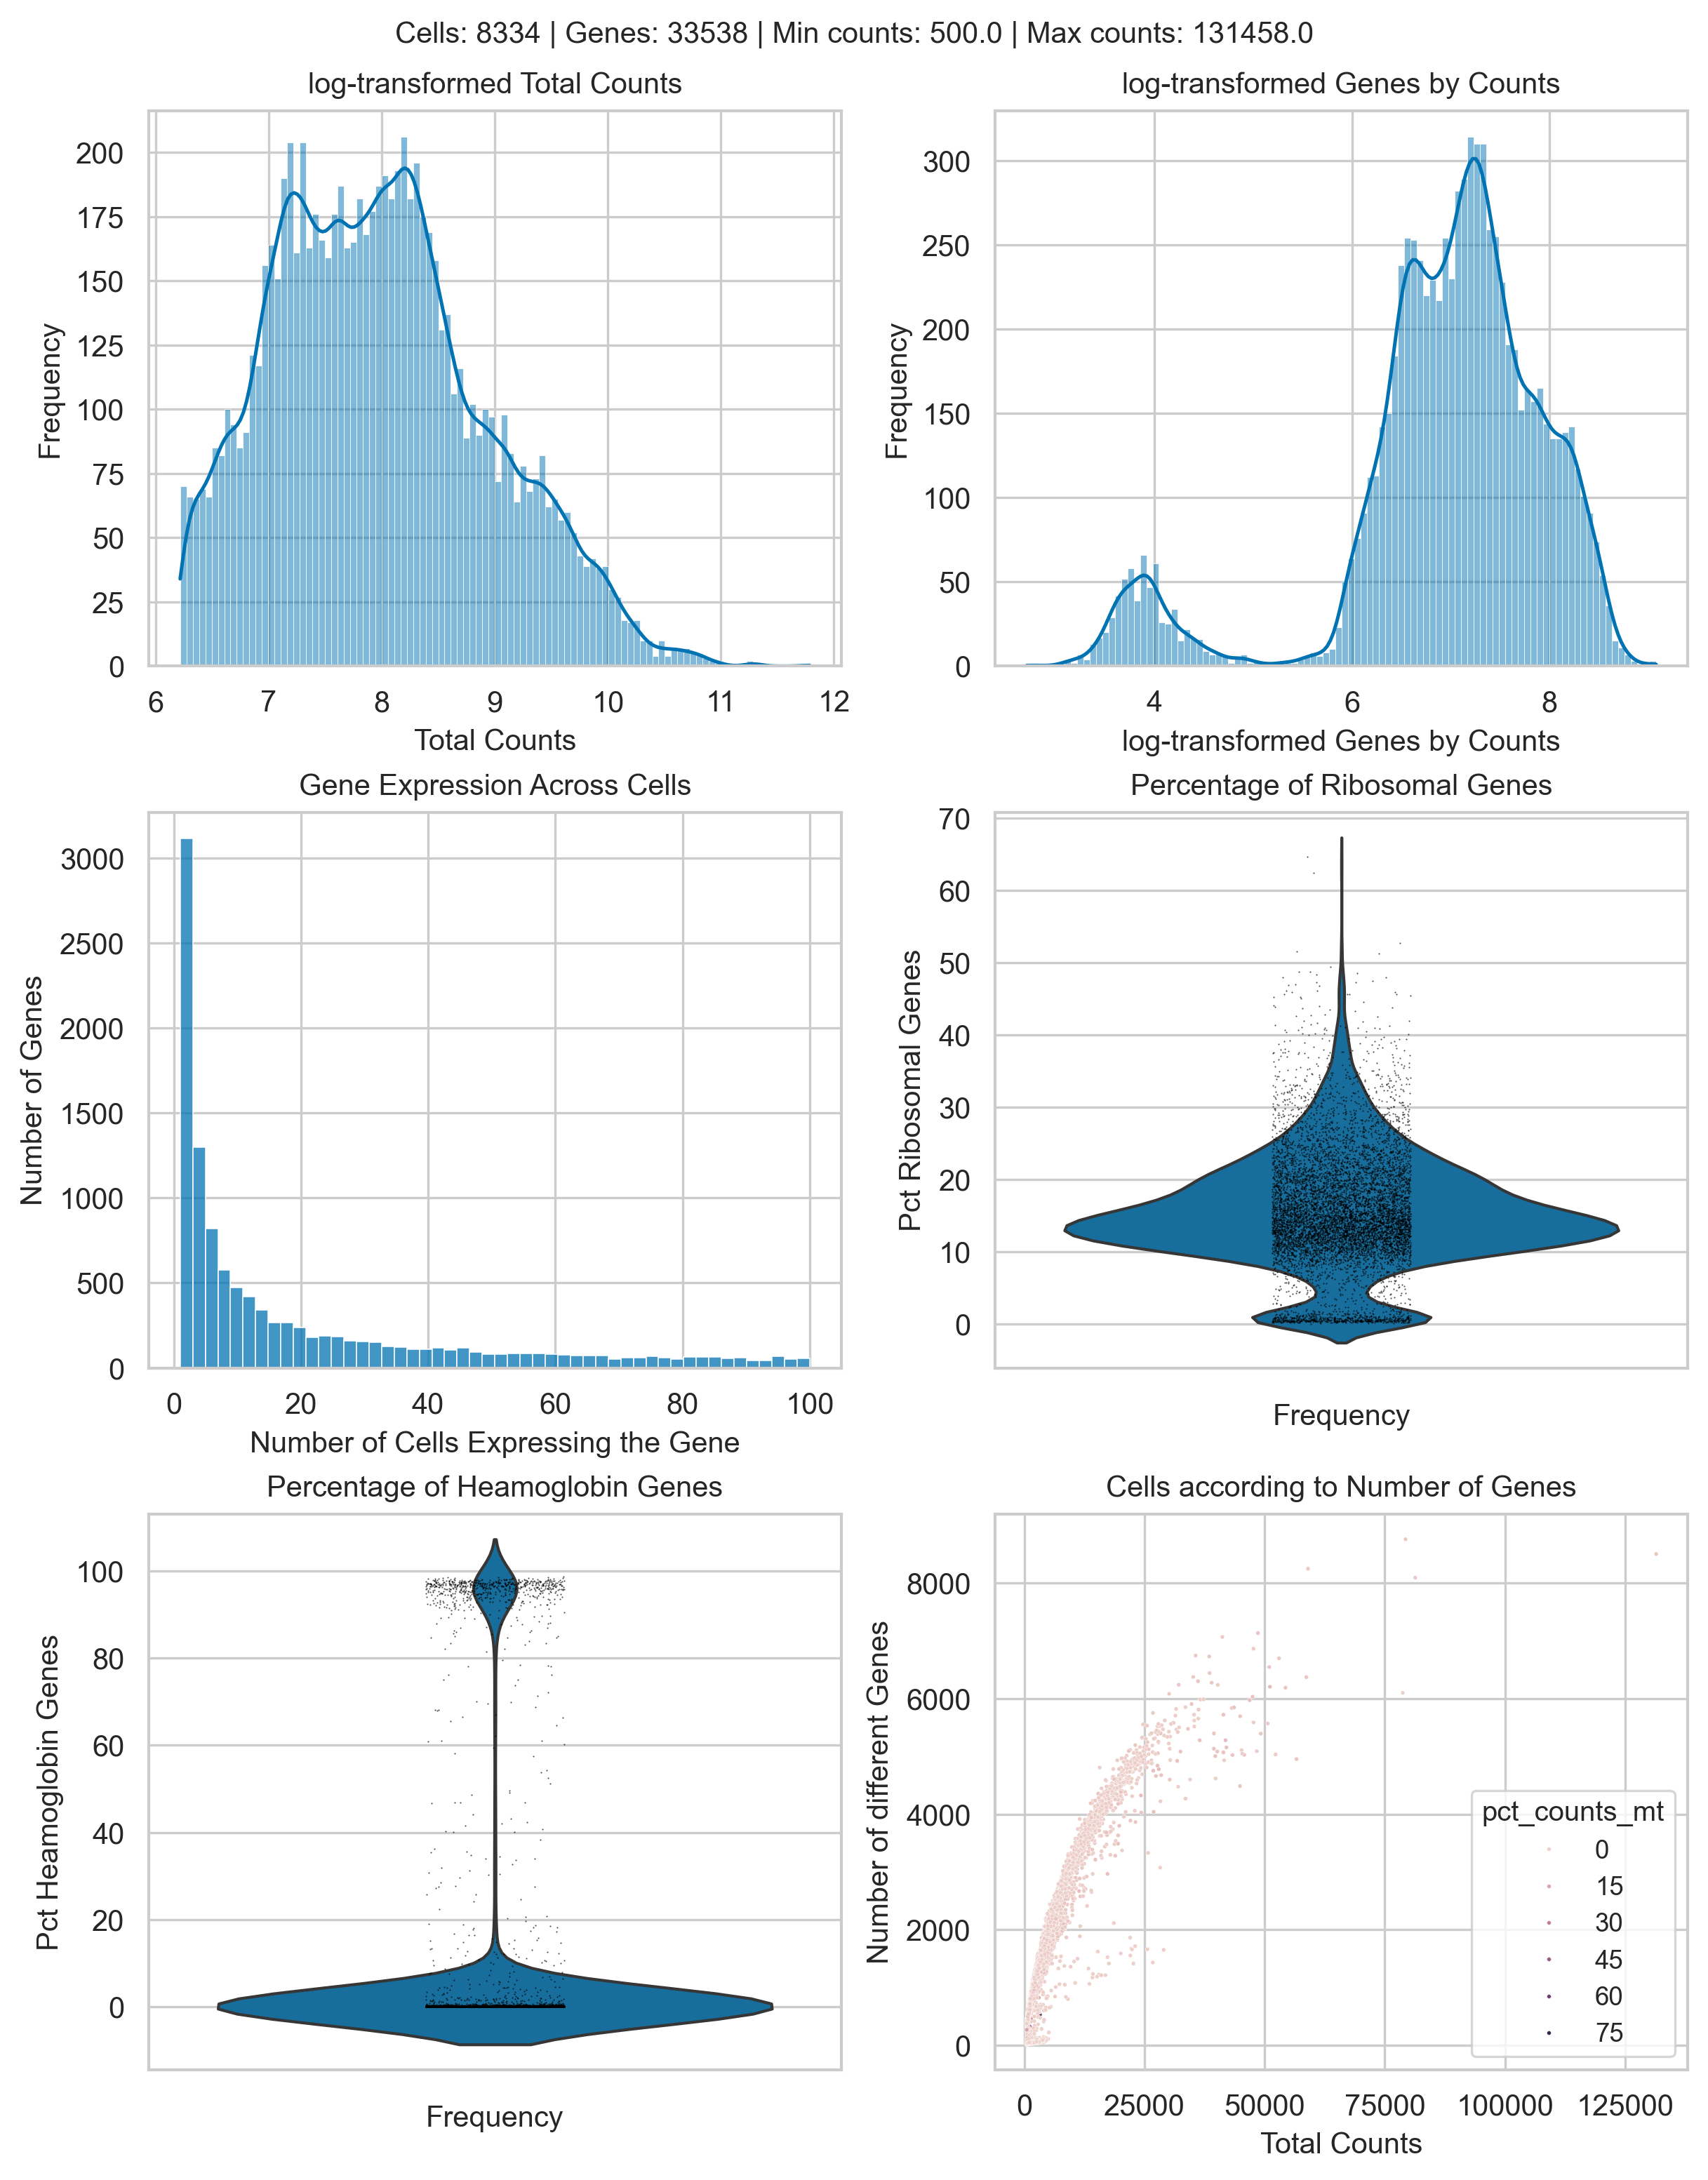

In [9]:
summary_text = (
    f"Cells: {adata.n_obs} | "f"Genes: {adata.n_vars} | "f"Min counts: {adata.obs['total_counts'].min()} | "f"Max counts: {adata.obs['total_counts'].max()}")

fig, axes = plt.subplots(3, 2, figsize=(8, 10), constrained_layout=True)
axes = axes.flatten()
fig.suptitle(summary_text, fontsize=10, y=1.02)

#1a How Many Times Cells have certain num Genes
sns.histplot(adata.obs["log1p_total_counts"], kde=True, ax=axes[0], bins=100, kde_kws={'bw_adjust': 0.5})
axes[0].set_title("log-transformed Total Counts")
axes[0].set_xlabel("Total Counts")
axes[0].set_ylabel("Frequency")

#1b How Many Times Cells have certain num Different Genes
sns.histplot(adata.obs["log1p_n_genes_by_counts"], kde=True, ax=axes[1], bins=100, kde_kws={'bw_adjust': 0.5})
axes[1].set_title("log-transformed Genes by Counts")
axes[1].set_xlabel("log-transformed Genes by Counts")
axes[1].set_ylabel("Frequency")

#1c  How many Genes Expressed in certain num Cells
sns.histplot(frequency_table.index.repeat(frequency_table.values), bins=50, binrange=(1, 100), ax=axes[2])
axes[2].set_title("Gene Expression Across Cells")
axes[2].set_xlabel("Number of Cells Expressing the Gene")
axes[2].set_ylabel("Number of Genes")

#1d
sns.violinplot(y=adata.obs["pct_counts_ribo"], ax=axes[3],  width=0.8, density_norm="width", inner=None)
sns.stripplot(y=adata.obs["pct_counts_ribo"], ax=axes[3], color="black", jitter=0.1, size=0.5, alpha=0.7)
axes[3].set_title("Percentage of Ribosomal Genes")
axes[3].set_xlabel("Frequency")
axes[3].set_ylabel("Pct Ribosomal Genes")

#1e
sns.violinplot(y=adata.obs["pct_counts_hb"], ax=axes[4],  width=0.8, inner=None)
sns.stripplot(y=adata.obs["pct_counts_hb"], ax=axes[4], color="black", jitter=0.1, size=0.5, alpha=0.7)
axes[4].set_title("Percentage of Heamoglobin Genes")
axes[4].set_xlabel("Frequency")
axes[4].set_ylabel("Pct Heamoglobin Genes")

#1f
sns.scatterplot(x=adata.obs["total_counts"], y=adata.obs["n_genes_by_counts"], hue=adata.obs["pct_counts_mt"], ax=axes[5], s=2)
axes[5].set_title("Cells according to Number of Genes")
axes[5].set_xlabel("Total Counts")
axes[5].set_ylabel("Number of different Genes")

plt.savefig(ADATA_DIR / f"{env}" / f"{patient}_1.png", dpi=300, bbox_inches="tight")

Filtering Cells / Genes

In [10]:
#cell-level filter
low_counts = adata.obs["total_counts"] < 500
high_mt = adata.obs.apply(
    lambda row: row["pct_counts_mt"] > (20 if row["condition"] == "N" else 40),
    axis=1) #20 for Normal samples, 40 for Her2/TN
high_hb = adata.obs.apply(
    lambda row: row["pct_counts_hb"] > (3),
    axis=1)
high_counts = adata.obs["total_counts"] > 40000

cell_mask = ~(low_counts | high_mt | high_hb | high_counts)
adata = adata[cell_mask, :].copy()

print(f"Number of genes after cell filter: {adata.n_vars}")
print(f"After QC filtering: {adata.n_obs} cells, {adata.n_vars} genes")

Number of genes after cell filter: 33538
After QC filtering: 7441 cells, 33538 genes


In [11]:
def recompute_qc(adata):
    sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True)
    return adata

Doublett Deletion/Deletion

In [12]:
%load_ext rpy2.ipython

In [13]:
%%R
print(R.version.string)

[1] "R version 4.6.0 (2026-04-24)"


In [14]:
#import rpy2.robjects as ro
#ro.r('.libPaths(c(.libPaths(), "/Library/Frameworks/R.framework/Versions/4.4-arm64/Resources/library"))')

In [15]:
%%R
library(BiocParallel)
library(SingleCellExperiment)

Loading required package: SummarizedExperiment
Loading required package: MatrixGenerics
Loading required package: matrixStats

Attaching package: ‘MatrixGenerics’

The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,
    rowOrderStats, rowProds, rowQuantiles, rowRanges, ro

In [16]:
%%R
library(scDblFinder)
print("Doublet Libraries")


[1] "Doublet Libraries"


In [17]:
from rpy2.robjects import r, globalenv
from scipy.sparse import csc_matrix
import rpy2.robjects as ro
from rpy2.robjects.packages import importr

X_csc = csc_matrix(adata.X.T)
coo = X_csc.tocoo()

Matrix = importr("Matrix")

data_mat_r = Matrix.sparseMatrix(
    i=ro.IntVector(coo.row + 1),#1-based indexing
    j=ro.IntVector(coo.col + 1),
    x=ro.FloatVector(coo.data),
    dims=ro.IntVector(coo.shape)
)
globalenv["data_mat"] = data_mat_r


In [18]:
%%R

set.seed(123)
sce <- scDblFinder(
    SingleCellExperiment(
        list(counts=data_mat),
    )
)
doublet_score = sce$scDblFinder.score
doublet_class = sce$scDblFinder.class

Creating ~5953 artificial doublets...
Dimensional reduction
Evaluating kNN...
Training model...
iter=0, 1530 cells excluded from training.
iter=1, 1540 cells excluded from training.
iter=2, 1510 cells excluded from training.
Threshold found:0.481
622 (8.4%) doublets called
In addition: Warning messages:
1: In .local(x, ...) : 'normalizeCounts' is deprecated.
Use 'scrapper::normalizeCounts' instead.
See help("Deprecated")
2: In .local(x, ...) : 'librarySizeFactors' is deprecated.
Use 'scrapper::centerSizeFactors' instead.
See help("Deprecated")


In [19]:
doublet_score = np.array(ro.globalenv["doublet_score"])
doublet_class = np.array(ro.globalenv["doublet_class"]).astype(str)

adata.obs["scDblFinder_score"] = doublet_score
adata.obs["scDblFinder_class"] = doublet_class
print(adata.obs["scDblFinder_class"].dtype)
adata.obs["scDblFinder_class"] = adata.obs["scDblFinder_class"].astype(str)
print(adata.obs["scDblFinder_class"].dtype)
print(adata.obs["scDblFinder_class"].value_counts())

print(len(doublet_class))
print(adata.n_obs)
print(np.unique(doublet_class))
adata.obs["scDblFinder_class"] = adata.obs["scDblFinder_class"].map({
    "1": "singlet",
    "2": "doublet"
})


object
object
scDblFinder_class
1    6819
2     622
Name: count, dtype: int64
7441
7441
['1' '2']


Text(0, 0.5, 'Number of different Genes')

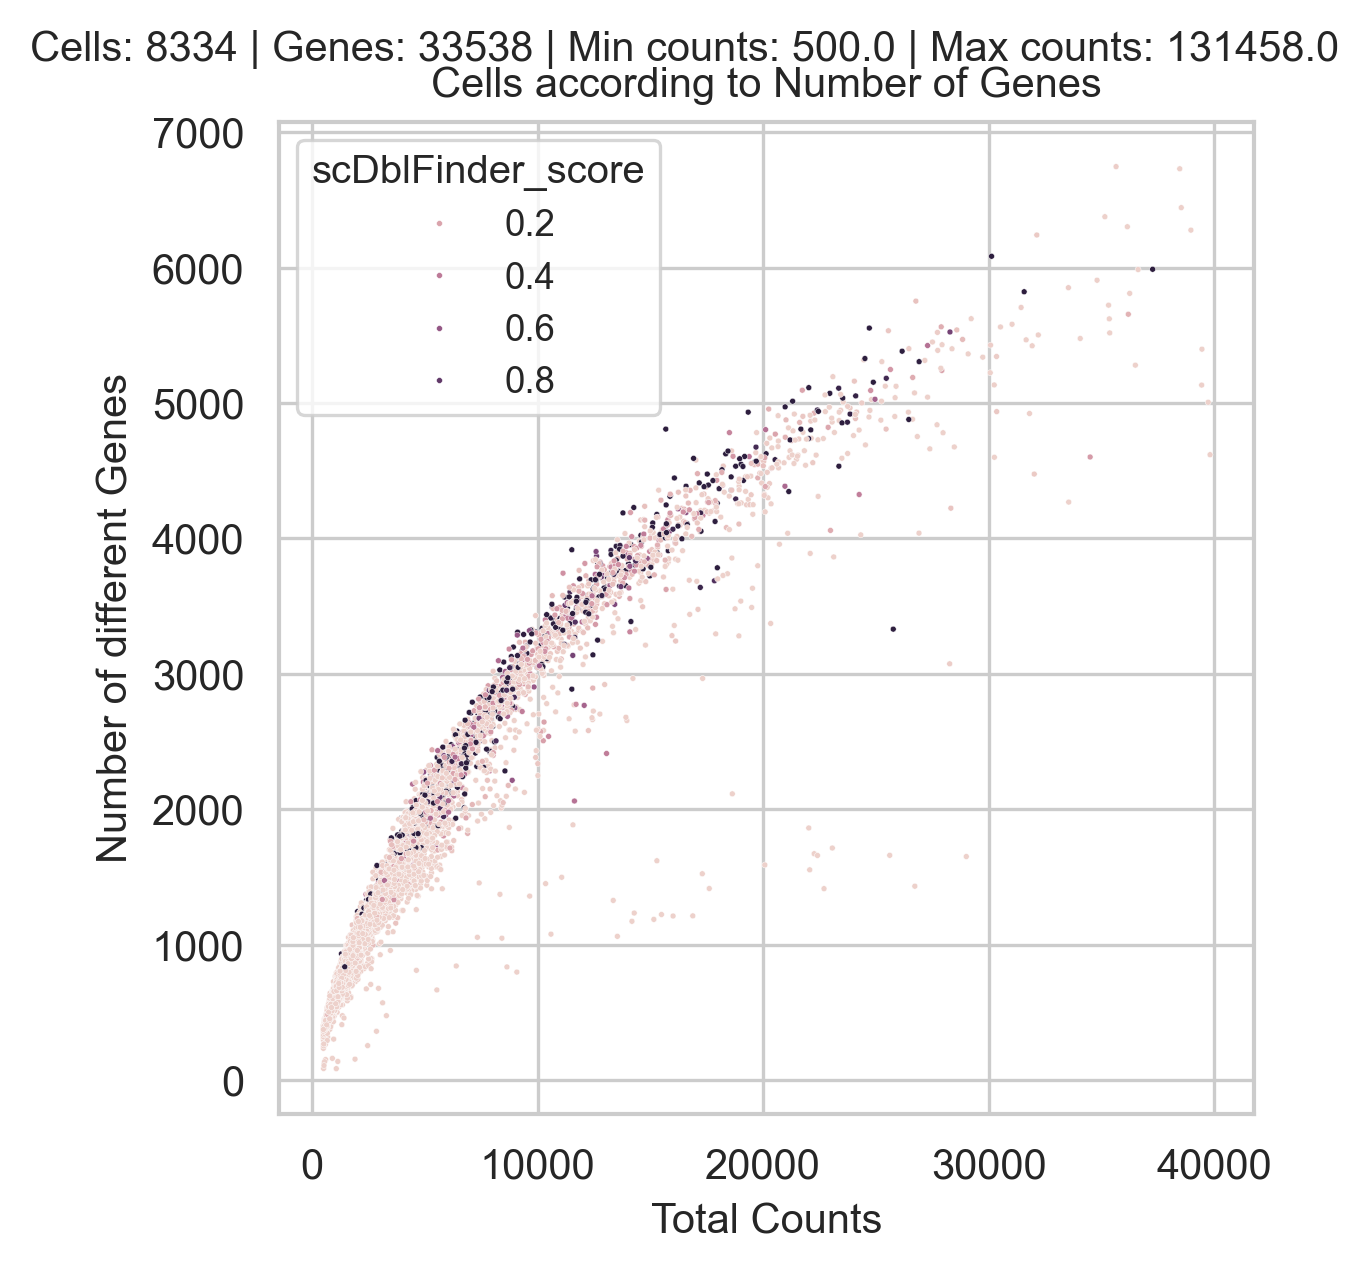

In [20]:
fig, axes = plt.subplots(1, 1, figsize=(4, 4), constrained_layout=True)
fig.suptitle(summary_text, fontsize=10, y=1.02)

sns.scatterplot(
    x=adata.obs["total_counts"],
    y=adata.obs["n_genes_by_counts"],
    hue=adata.obs["scDblFinder_score"],
    ax=axes,#no indexing
    s=2
)
axes.set_title("Cells according to Number of Genes")
axes.set_xlabel("Total Counts")
axes.set_ylabel("Number of different Genes")

In [21]:
print(np.unique(doublet_class))
adata = adata[adata.obs["scDblFinder_class"] == "singlet"].copy()
print(f"Remaining cells: {adata.n_obs}")
print("adata.X shape:", adata.X.shape)

['1' '2']
Remaining cells: 6819
adata.X shape: (6819, 33538)


Inspection Plot 2:

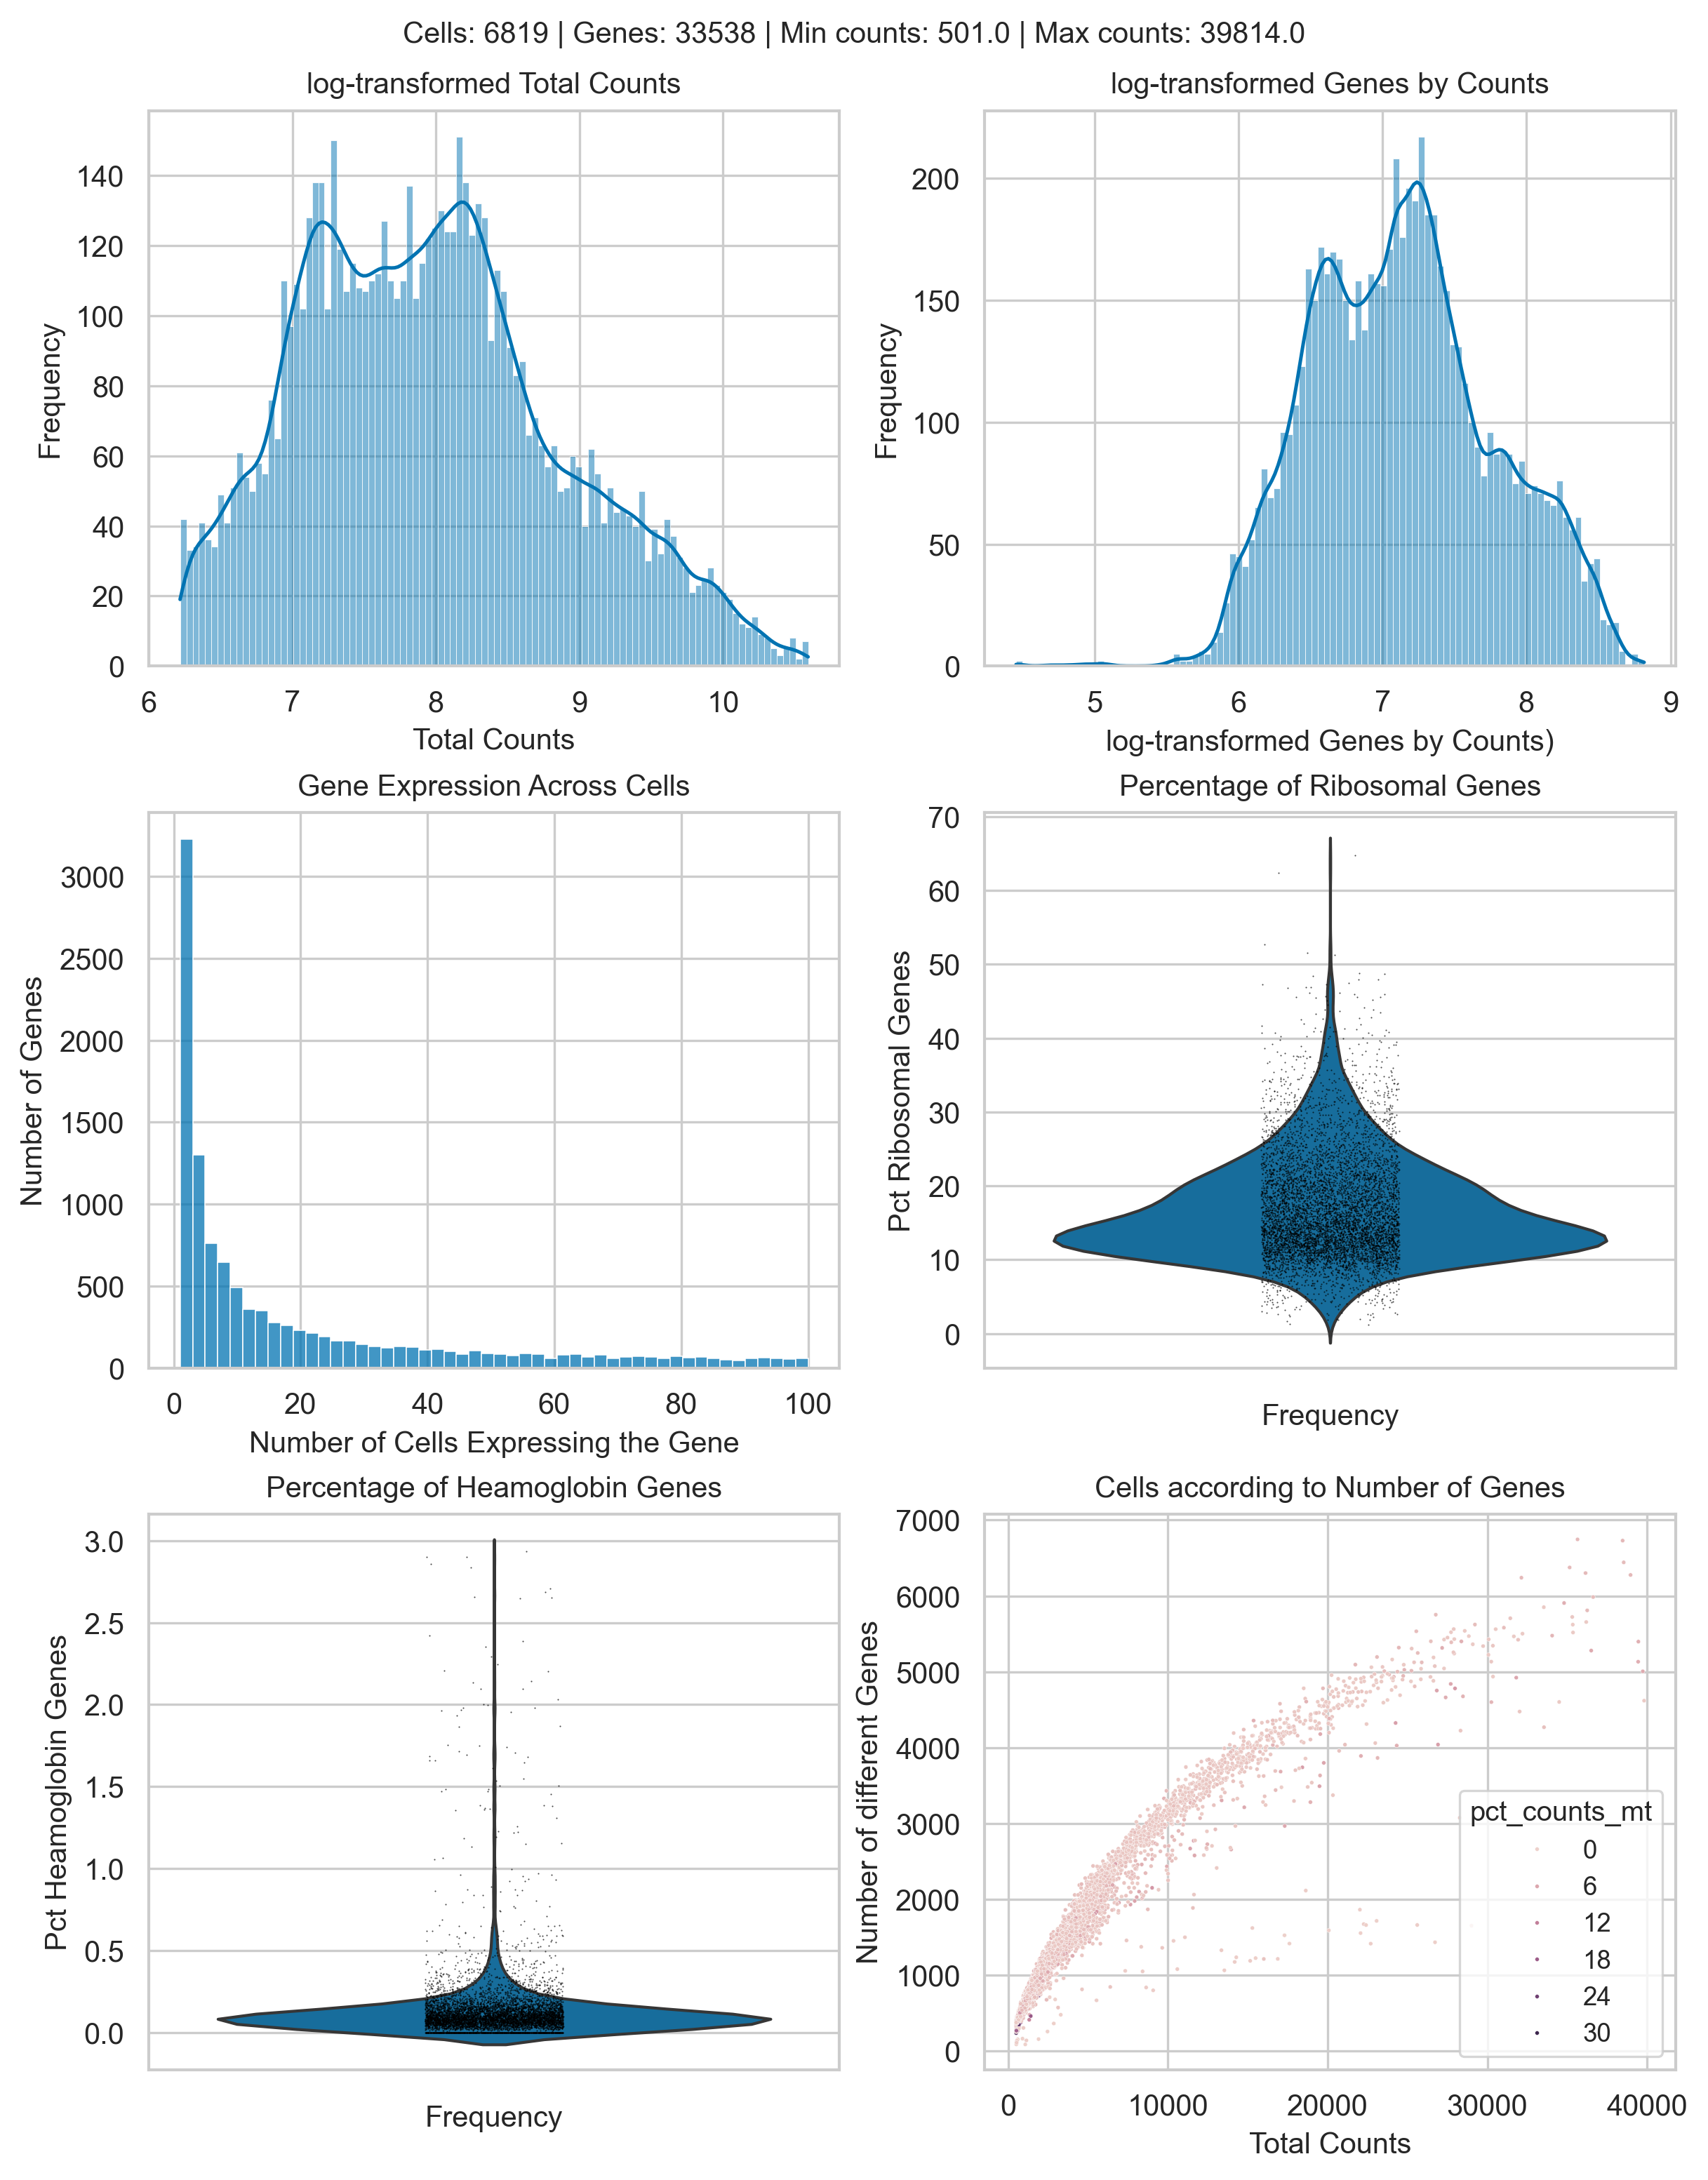

In [22]:
#recomputing attributes before replotting
adata = recompute_qc(adata)
gene_counts = pd.Series(adata.var['n_cells_by_counts'])
frequency_table = gene_counts.value_counts().sort_index()

summary_text = (
    f"Cells: {adata.n_obs} | "f"Genes: {adata.n_vars} | "f"Min counts: {adata.obs['total_counts'].min()} | "f"Max counts: {adata.obs['total_counts'].max()}")

fig, axes = plt.subplots(3, 2, figsize=(8, 10), constrained_layout=True)
axes = axes.flatten()
fig.suptitle(summary_text, fontsize=10, y=1.02)

#2a How Many Times Cells have certain num Genes
sns.histplot(adata.obs["log1p_total_counts"], kde=True, ax=axes[0], bins=100, kde_kws={'bw_adjust': 0.5})
axes[0].set_title("log-transformed Total Counts")
axes[0].set_xlabel("Total Counts")
axes[0].set_ylabel("Frequency")

#2b How Many Times Cells have certain num Different Genes
sns.histplot(adata.obs["log1p_n_genes_by_counts"], kde=True, ax=axes[1], bins=100, kde_kws={'bw_adjust': 0.5})
axes[1].set_title("log-transformed Genes by Counts")
axes[1].set_xlabel("log-transformed Genes by Counts)")
axes[1].set_ylabel("Frequency")

#2c How many Genes Expressed in certain num Cells
sns.histplot(frequency_table.index.repeat(frequency_table.values), bins=50, binrange=(1, 100), ax=axes[2])
axes[2].set_title("Gene Expression Across Cells")
axes[2].set_xlabel("Number of Cells Expressing the Gene")
axes[2].set_ylabel("Number of Genes")

#2d
sns.violinplot(y=adata.obs["pct_counts_ribo"], ax=axes[3],  width=0.8, density_norm="width", inner=None)
sns.stripplot(y=adata.obs["pct_counts_ribo"], ax=axes[3], color="black", jitter=0.1, size=0.5, alpha=0.7)
axes[3].set_title("Percentage of Ribosomal Genes")
axes[3].set_xlabel("Frequency")
axes[3].set_ylabel("Pct Ribosomal Genes")

#2e
sns.violinplot(y=adata.obs["pct_counts_hb"], ax=axes[4],  width=0.8, inner=None)
sns.stripplot(y=adata.obs["pct_counts_hb"], ax=axes[4], color="black", jitter=0.1, size=0.5, alpha=0.7)
axes[4].set_title("Percentage of Heamoglobin Genes")
axes[4].set_xlabel("Frequency")
axes[4].set_ylabel("Pct Heamoglobin Genes")

#2f
sns.scatterplot(x=adata.obs["total_counts"], y=adata.obs["n_genes_by_counts"], hue=adata.obs["pct_counts_mt"], ax=axes[5], s=2)
axes[5].set_title("Cells according to Number of Genes")
axes[5].set_xlabel("Total Counts")
axes[5].set_ylabel("Number of different Genes")

plt.savefig(rf"/Volumes/TOSHIBA EXT/Nowotny/{env}/{patient}_2.png", dpi=300, bbox_inches="tight")

In [23]:
#saving Raw counts
adata.layers["raw_counts"] = adata.X.copy()
raw_counts = adata.layers["raw_counts"]

Normalisation

-Log1p

In [24]:
#Normalizing from raw layer
norm = sc.pp.normalize_total(adata, target_sum=1e4, layer="raw_counts", inplace=False)

adata.layers["norm"] = norm["X"]
adata.layers["log1p_norm"] = sc.pp.log1p(norm["X"], copy=True)

-Scran

In [25]:
%%R
library(scran)
library(Matrix)
library(BiocParallel)

Loading required package: scuttle


In [26]:
#Preliminary clustering for differentiated normalisation
adata_pp = adata.copy()
sc.pp.normalize_total(adata_pp)
sc.pp.log1p(adata_pp)
sc.pp.pca(adata_pp, n_comps=15)
sc.pp.neighbors(adata_pp)
sc.tl.leiden(adata_pp, key_added="groups")
data_mat = adata_pp.X.T

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [27]:
import rpy2.robjects as ro
from scipy.sparse import csc_matrix
from rpy2.robjects.packages import importr

Matrix = importr("Matrix")

if not isinstance(data_mat, csc_matrix):
    data_mat = data_mat.tocsc()
coo = data_mat.tocoo()

data_mat_r = Matrix.sparseMatrix(
    i=ro.IntVector(coo.row + 1),#1-based indexing
    j=ro.IntVector(coo.col + 1),
    x=ro.FloatVector(coo.data),
    dims=ro.IntVector(coo.shape)
)
ro.globalenv["data_mat"] = data_mat_r
ro.globalenv["input_groups"] = ro.StrVector(adata_pp.obs["groups"].tolist())
del adata_pp

In [28]:
%%R
input_groups <- as.factor(input_groups)

size_factors <- sizeFactors(
    computeSumFactors(
        SingleCellExperiment(list(counts=data_mat)), clusters = input_groups, min.mean = 0.1, BPPARAM = MulticoreParam())
)

In [29]:
size_factors=ro.globalenv["size_factors"]
adata.obs["size_factors"] = size_factors
scran = adata.layers["raw_counts"] / adata.obs["size_factors"].values[:, None]
scran = scran.tocsr()
#scran.data = np.log1p(scran.data)

adata.layers["scran_normalization"] = scran

scran_log1p = scran.copy()
scran_log1p.data = np.log1p(scran.data)
adata.layers["scran_log1p"] = scran_log1p

-Analytic Pearson Residuals

In [30]:
analytic_pearson = sc.experimental.pp.normalize_pearson_residuals(adata, layer="raw_counts", inplace=False)
adata.layers["analytic_pearson_residuals"] = analytic_pearson["X"]

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/scanpy/experimental/pp/_normalization.py:76: RuntimeWarning: invalid value encountered in divide
  residuals = diff / np.sqrt(mu + mu**2 / theta)


Feature Selection

In [31]:
def scipy_csc_to_r_dgc(mat):
    mat = mat.tocsc()
    i = ro.IntVector(mat.indices)#R is 1-indexed
    p = ro.IntVector(mat.indptr)
    x = ro.FloatVector(mat.data)
    dims = ro.IntVector(mat.shape)
    return ro.r["new"]("dgCMatrix", i=i, p=p, x=x, Dim=dims)

counts = adata.layers["raw_counts"].T
counts_r = scipy_csc_to_r_dgc(counts)

ro.globalenv["raw_counts"] = counts_r
ro.globalenv["gene_names"] = ro.StrVector(adata.var_names)
ro.globalenv["cell_names"] = ro.StrVector(adata.obs_names)

In [32]:
%%R
library(Matrix)
library(scry)

rownames(raw_counts) <- gene_names
colnames(raw_counts) <- cell_names

sce <- SingleCellExperiment(
    assays = list(counts = raw_counts)
)
sce <- devianceFeatureSelection(sce)

binomial_deviance <- rowData(sce)$binomial_deviance

In [33]:
binomial_deviance = np.array(ro.r["binomial_deviance"])
adata.var["binomial_deviance"] = binomial_deviance

#filtering Featured Genes
feat_genes = (adata.var.get("mt", False) | adata.var.get("ribo", False) | adata.var.get("hb", False)
)

cell_cycle_gene_list = cell_cycle_genes['G1/S'] + cell_cycle_genes['G2/M']
cell_cycle_mask = adata.var_names.isin(cell_cycle_gene_list)

exclude_mask = feat_genes | cell_cycle_mask

ranked_idx = np.argsort(binomial_deviance)[::-1]
filtered_idx = [i for i in ranked_idx if not exclude_mask.iloc[i]]

#selecting top N genes
N = 2000
selected_idx = filtered_idx[:N]

mask = np.zeros(adata.n_vars, dtype=bool)
mask[selected_idx] = True

adata.var["highly_deviant"] = mask

#keeping compatibility with Scanpy naming
adata.var["highly_variable"] = adata.var["highly_deviant"]
top_genes = adata.var_names[adata.var["highly_deviant"]]
pd.Series(top_genes).to_csv(PROJECT_ROOT / env / "csv_saves" / "top2000_deviant_genes.csv", index=False, header=False)

PCA

In [34]:
adata.X = adata.layers["log1p_norm"]
sc.tl.pca(adata, svd_solver="arpack", n_comps=50, use_highly_variable=True)

explained_variance = adata.uns['pca']['variance_ratio'][:4] * 100
explained_var = adata.uns["pca"]["variance_ratio"] * 100

In [35]:
pc1 = adata.obsm["X_pca"][:, 0]
depth = adata.obs["total_counts"]

np.corrcoef(pc1, depth)[0, 1]

np.float64(0.5018053351089036)

tSNE

In [36]:
sc.tl.tsne(adata, use_rep="X_pca")

Inspection Plot3

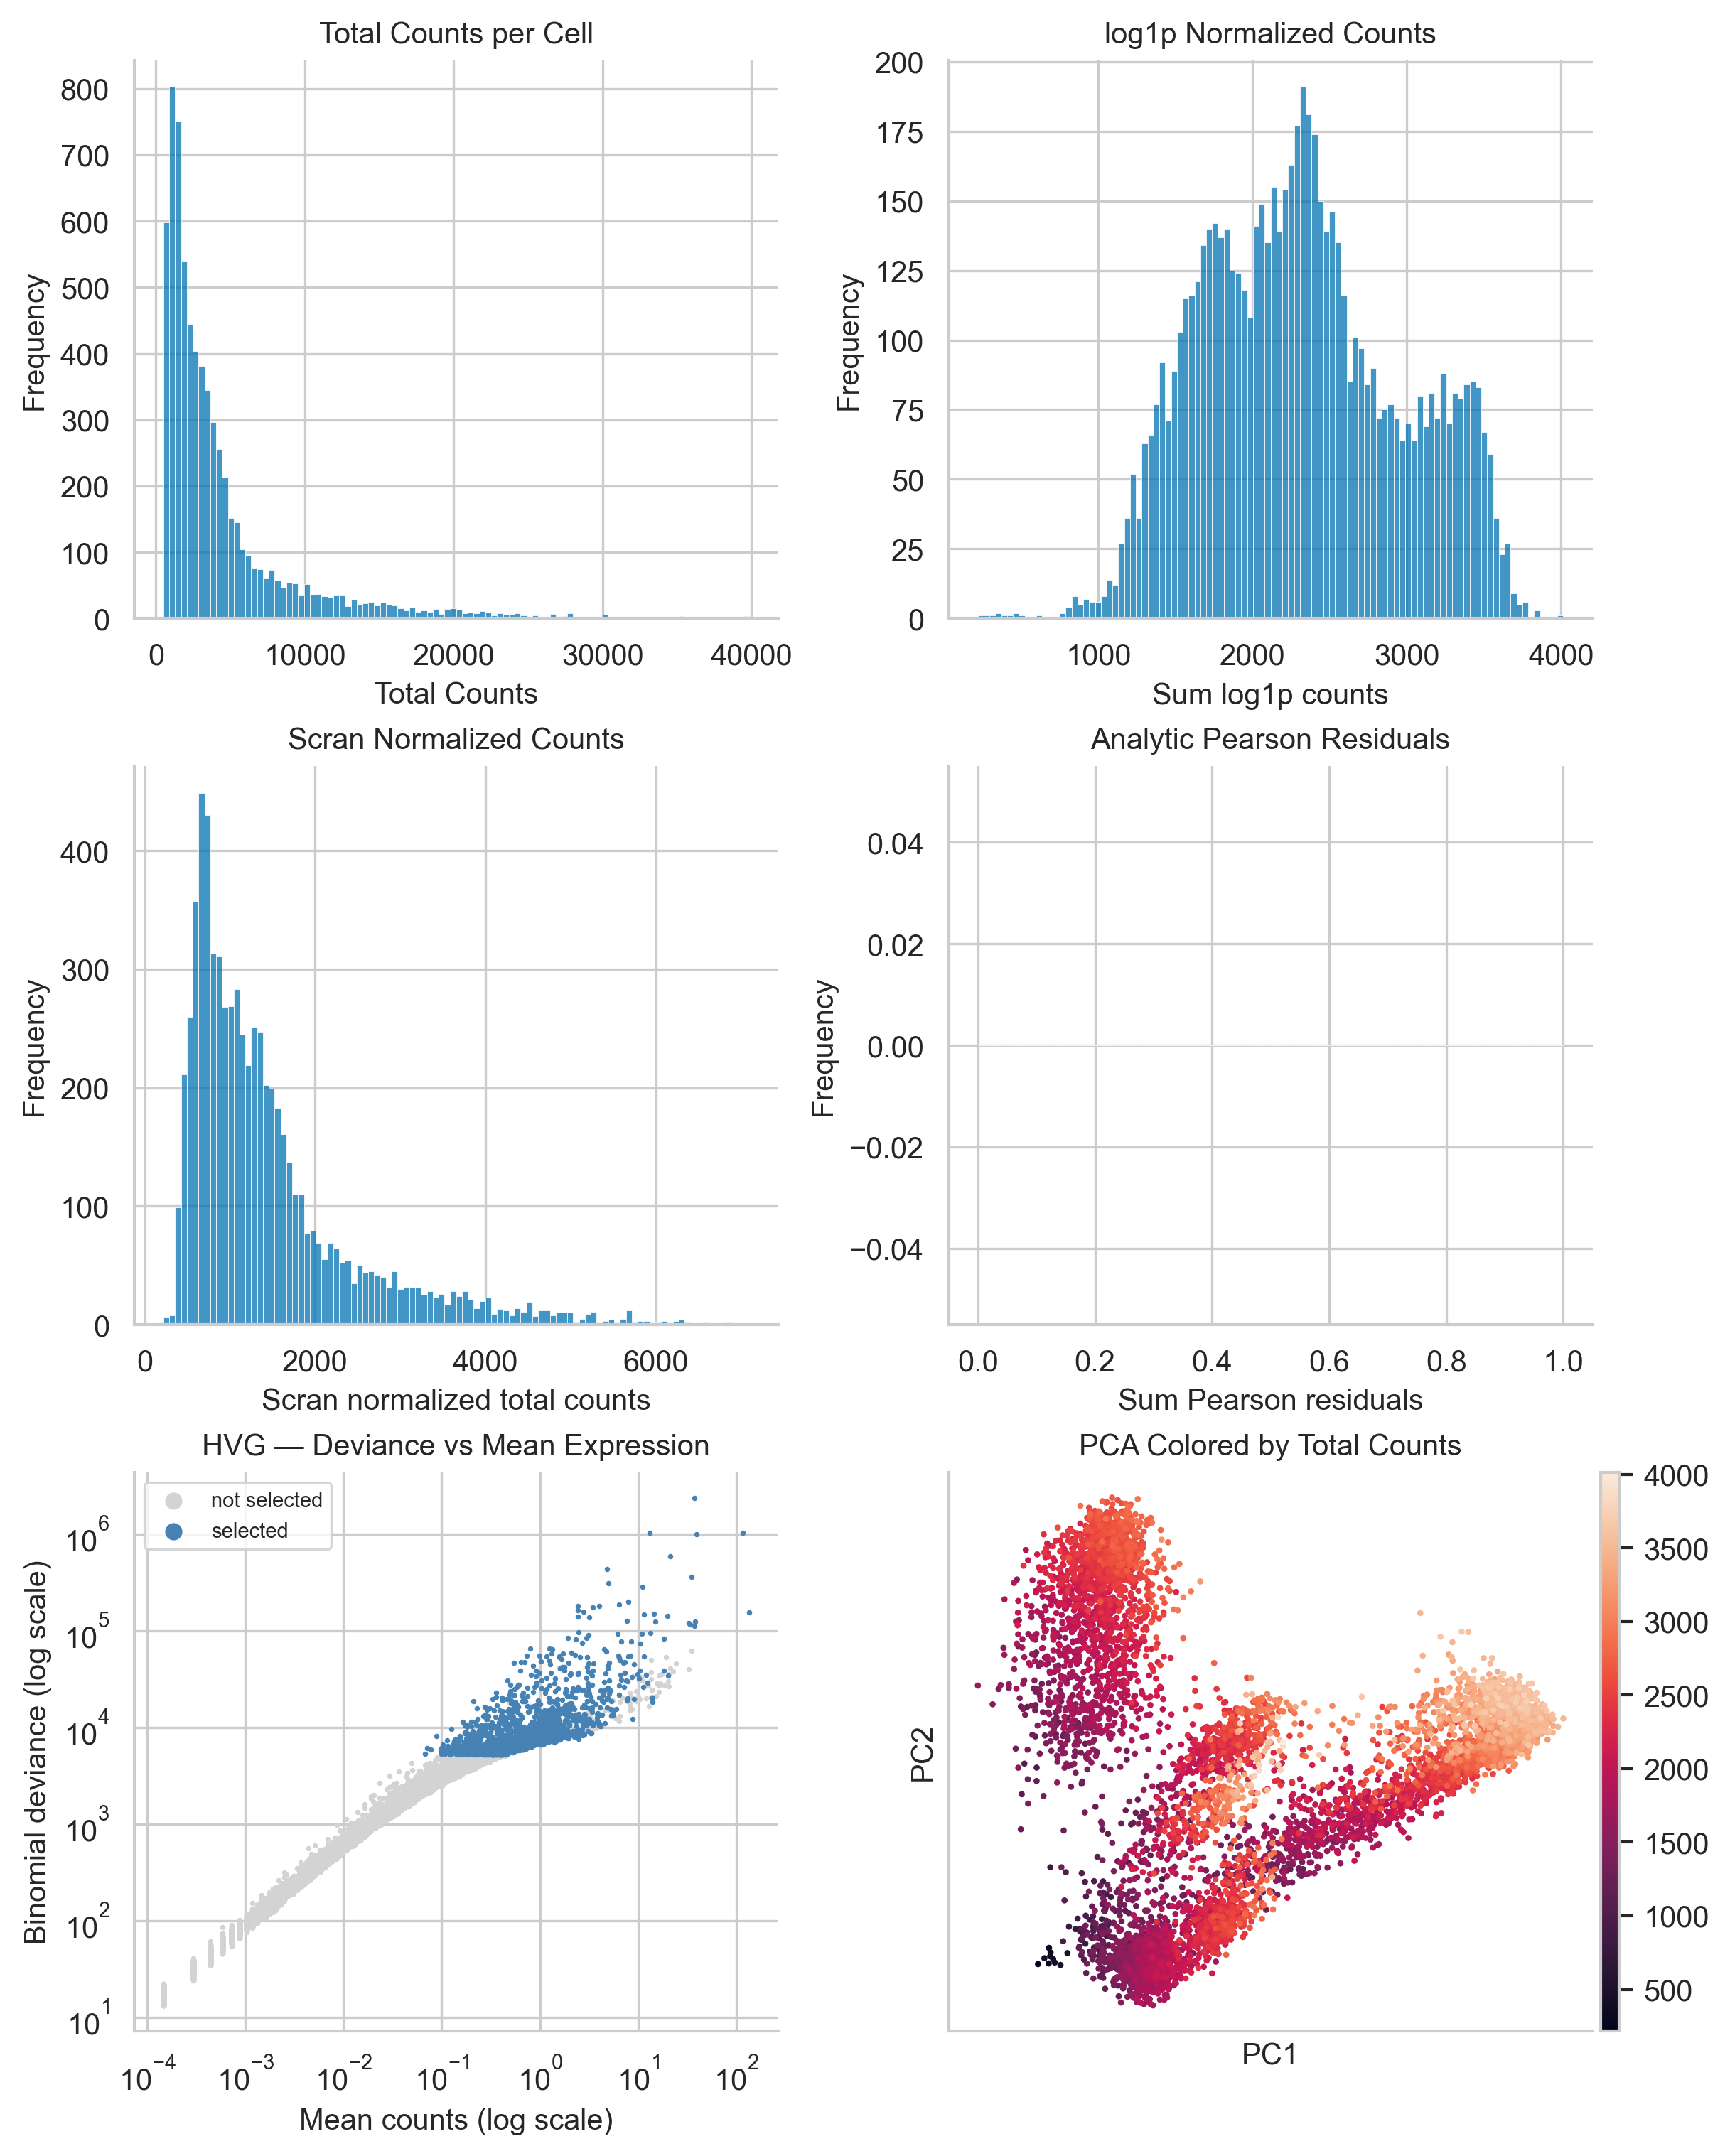

In [37]:
sc.pp.calculate_qc_metrics(adata, inplace=True)
adata = recompute_qc(adata)
fig, axes = plt.subplots(3, 2, figsize=(8, 10), constrained_layout=True)
axes = axes.flatten()

#3a Total counts
sns.histplot(np.array(adata.layers["raw_counts"].sum(1)).flatten(), bins=100, ax=axes[0])
axes[0].set_title("Total Counts per Cell")
axes[0].set_xlabel("Total Counts")
axes[0].set_ylabel("Frequency")

#3b log1p normalized counts
sns.histplot(np.array(adata.layers["log1p_norm"].sum(1)).flatten(), bins=100, ax=axes[1])
axes[1].set_title("log1p Normalized Counts")
axes[1].set_xlabel("Sum log1p counts")
axes[1].set_ylabel("Frequency")


#3c Scran normalized counts
sns.histplot(np.array(adata.layers["scran_log1p"].sum(1)).flatten(), bins=100, ax=axes[2])
axes[2].set_title("Scran Normalized Counts")
axes[2].set_xlabel("Scran normalized total counts")
axes[2].set_ylabel("Frequency")

#3d Analytic Pearson residuals
sns.histplot(np.array(adata.layers["analytic_pearson_residuals"].sum(1)).flatten(), bins=100, ax=axes[3])
axes[3].set_title("Analytic Pearson Residuals")
axes[3].set_xlabel("Sum Pearson residuals")
axes[3].set_ylabel("Frequency")

# 3e Deviance vs mean expression
mean_expr = np.array(adata.layers["raw_counts"].mean(axis=0)).flatten()
axes[4].scatter(
    mean_expr[~mask], binomial_deviance[~mask],
    s=1, c="lightgray", label="not selected"
)
axes[4].scatter(
    mean_expr[mask], binomial_deviance[mask],
    s=1, c="steelblue", label="selected"
)
axes[4].set_xscale("log")
axes[4].set_yscale("log")
axes[4].set_xlabel("Mean counts (log scale)")
axes[4].set_ylabel("Binomial deviance (log scale)")
axes[4].set_title("HVG — Deviance vs Mean Expression")
axes[4].legend(markerscale=5, fontsize=7)

#3f PCA scatter
sc.pl.pca_scatter(adata, color="total_counts", ax=axes[5], show=False)
axes[5].set_title("PCA Colored by Total Counts")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.savefig(rf"/Volumes/TOSHIBA EXT/Nowotny/{env}/{patient}_3.png", dpi=300)
plt.show()

Inspection Plot4

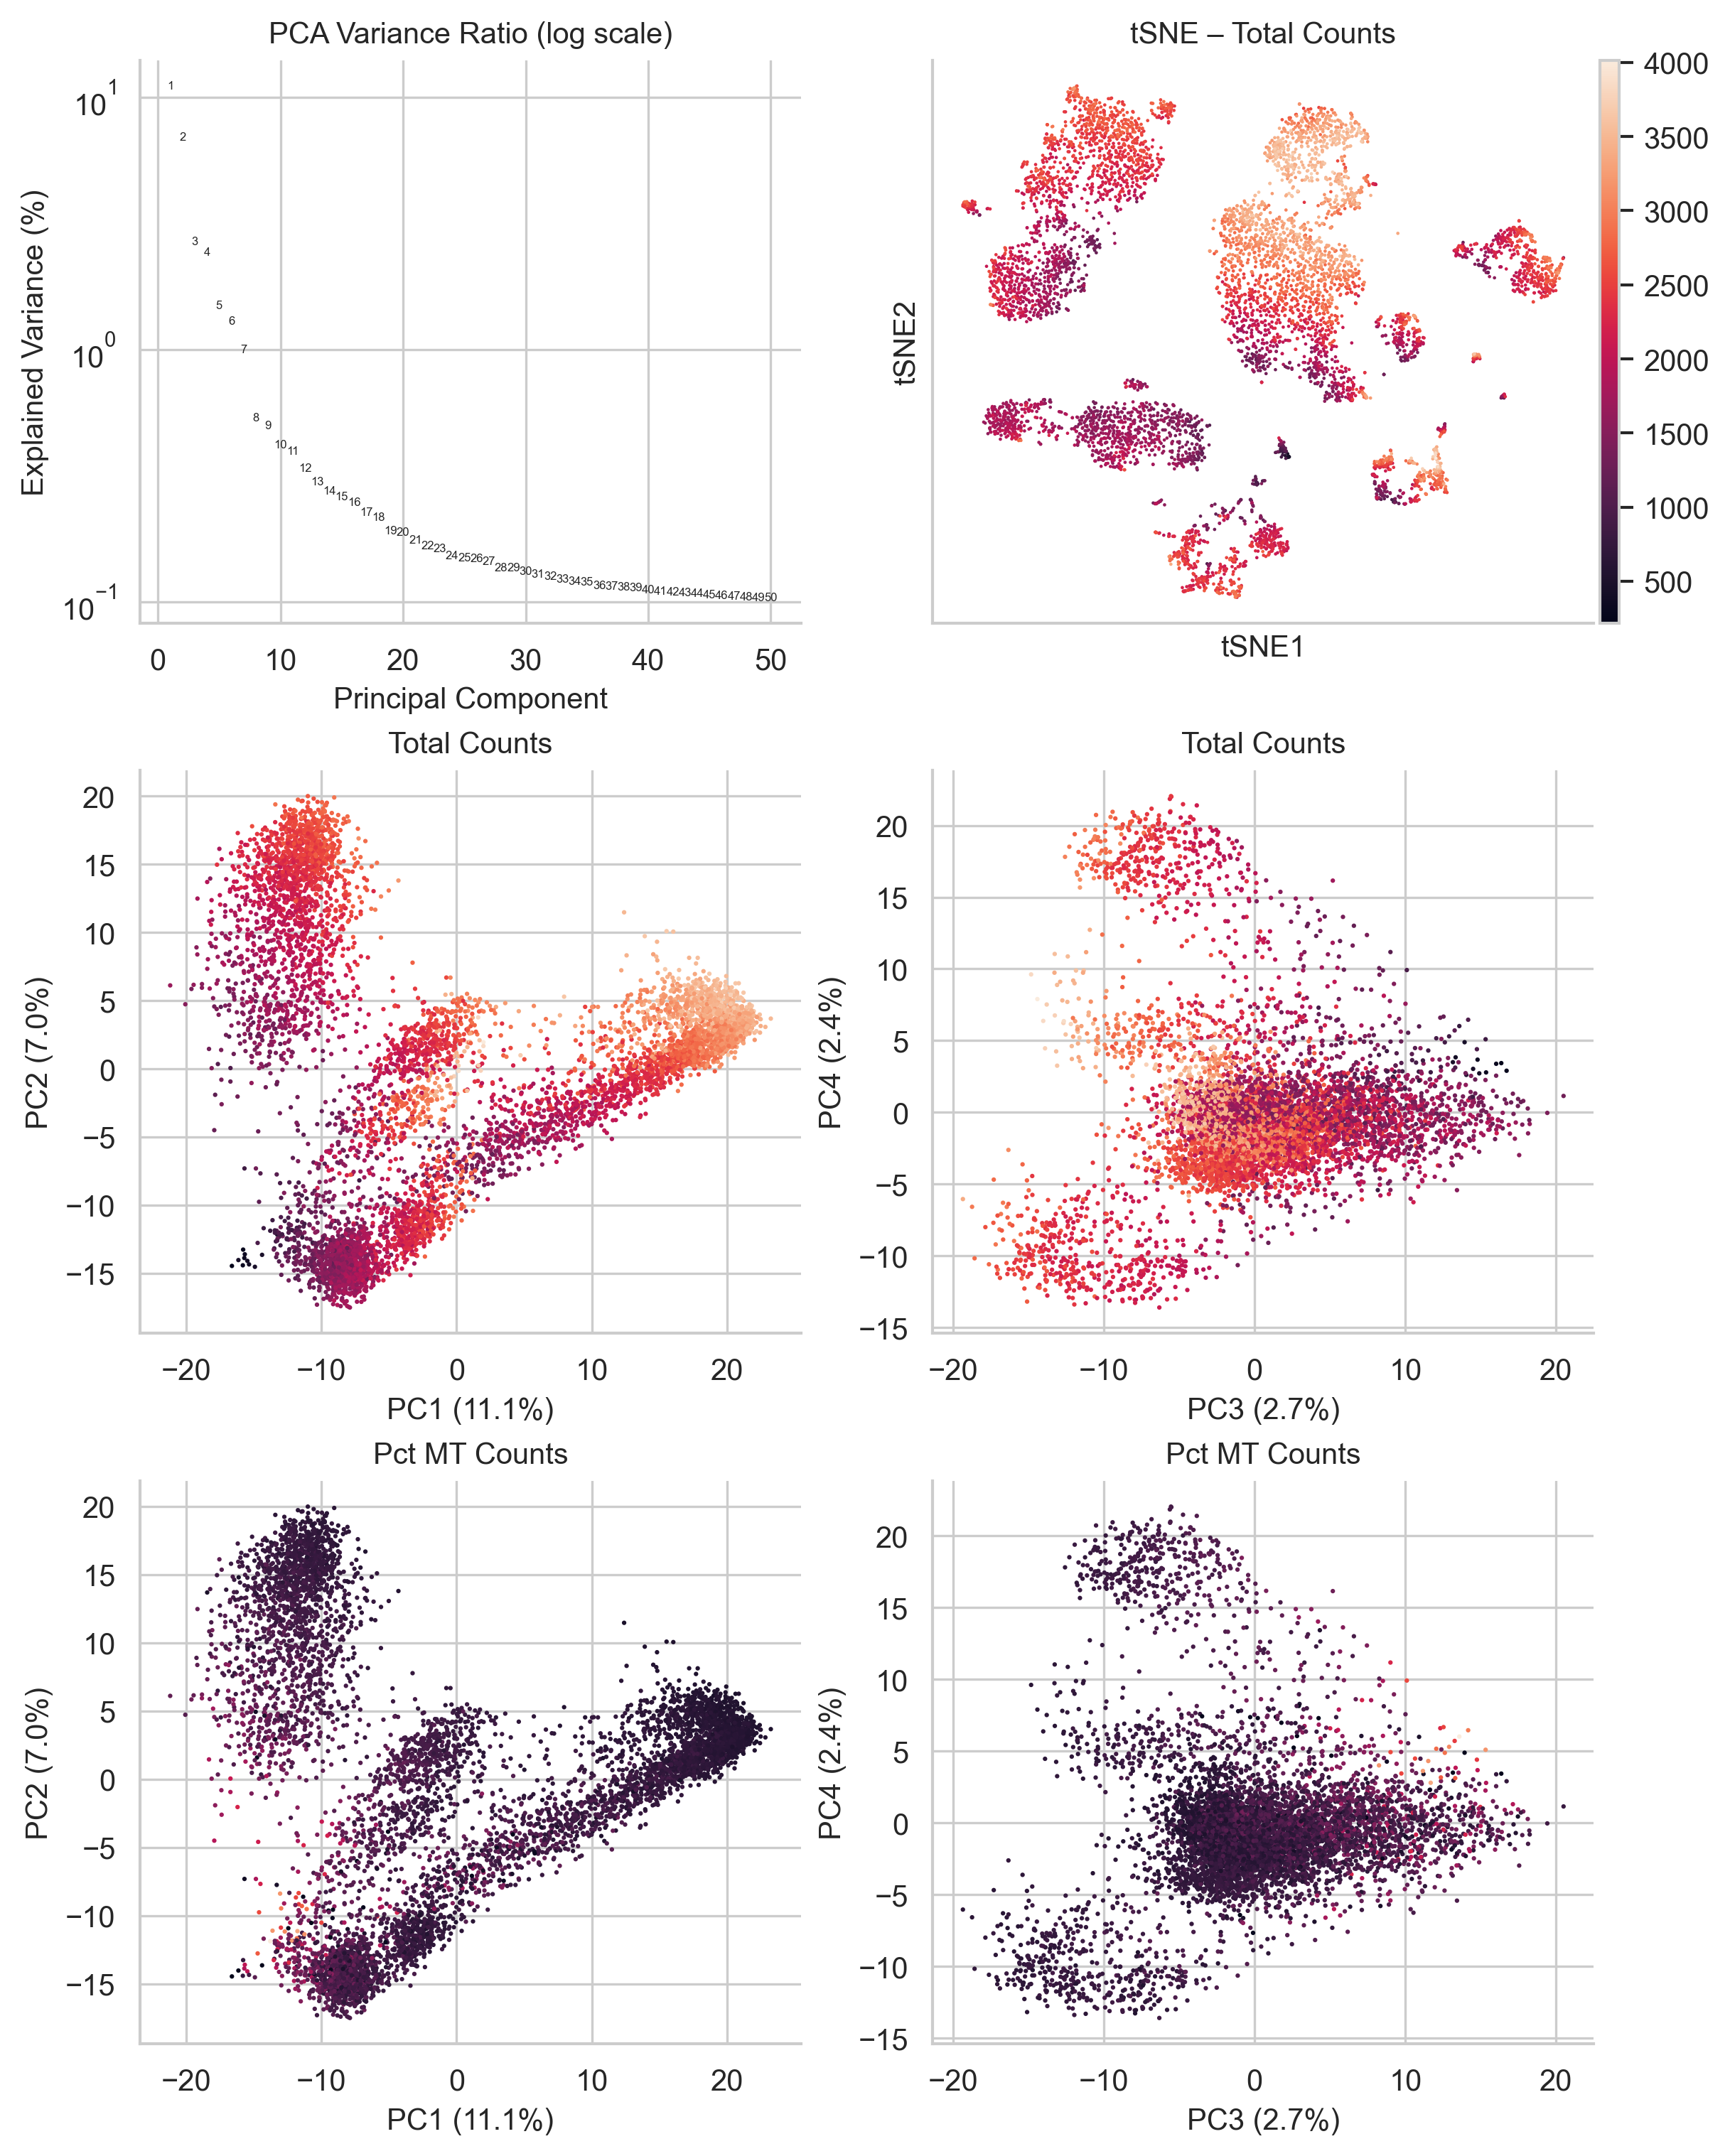

In [38]:
fig, axes = plt.subplots(3, 2, figsize=(8, 10), constrained_layout=True)
axes = axes.flatten()

#4a PC-Variance
var_ratio = adata.uns["pca"]["variance_ratio"][:50] * 100
var_ratio = np.clip(var_ratio, 1e-5, None)

axes[0].set_yscale("log")
axes[0].scatter(range(1, len(var_ratio)+1), var_ratio, alpha=0)
for i, var in enumerate(var_ratio):
    axes[0].text(i + 1, var, str(i + 1), ha="center", va="center", fontsize=4)
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance (%)")
axes[0].set_title("PCA Variance Ratio (log scale)")

#4b tSNE
sc.pl.tsne(adata, color="total_counts", ax=axes[1], size=5, show=False)
axes[1].set_title("tSNE – Total Counts")

#4c PC1 vs PC2 (total_counts)
X_pca = adata.obsm["X_pca"]

axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=adata.obs["total_counts"], s=0.5)
axes[2].set_xlabel(f"PC1 ({explained_var[0]:.1f}%)")
axes[2].set_ylabel(f"PC2 ({explained_var[1]:.1f}%)")
axes[2].set_title("Total Counts")

#4d PC3 vs PC4 (total_counts)
axes[3].scatter(X_pca[:, 2], X_pca[:, 3], c=adata.obs["total_counts"], s=0.5)
axes[3].set_xlabel(f"PC3 ({explained_var[2]:.1f}%)")
axes[3].set_ylabel(f"PC4 ({explained_var[3]:.1f}%)")
axes[3].set_title("Total Counts")

#4e PC1 vs PC2 (% MT)
axes[4].scatter(X_pca[:, 0], X_pca[:, 1], c=adata.obs["pct_counts_mt"], s=0.5)
axes[4].set_xlabel(f"PC1 ({explained_var[0]:.1f}%)")
axes[4].set_ylabel(f"PC2 ({explained_var[1]:.1f}%)")
axes[4].set_title("Pct MT Counts")

#4f PC3 vs PC4 (% MT)
axes[5].scatter(X_pca[:, 2], X_pca[:, 3], c=adata.obs["pct_counts_mt"], s=0.5)
axes[5].set_xlabel(f"PC3 ({explained_var[2]:.1f}%)")
axes[5].set_ylabel(f"PC4 ({explained_var[3]:.1f}%)")
axes[5].set_title("Pct MT Counts")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


plt.savefig(rf"/Volumes/TOSHIBA EXT/Nowotny/{env}/{patient}_4.png", dpi=300)

Prep for Integration

In [39]:
#preserving the important coloumns
var_cols_to_keep = ["highly_variable", "highly_deviant", "binomial_deviance", "mt", "ribo", "hb"]
var_to_save = adata.var[[col for col in var_cols_to_keep if col in adata.var.columns]].copy()

adata.layers["counts"] = adata.layers["raw_counts"]
del adata.layers["raw_counts"]
adata.layers["log1p"] = adata.layers["log1p_norm"]

layers_to_keep = ["counts", "log1p"]
for key in list(adata.layers.keys()):
    if key not in layers_to_keep:
        del adata.layers[key]

adata.X = adata.layers["counts"]
adata.obsm.clear()
adata.obsp.clear()
adata.uns.clear()

for col in var_to_save.columns:
    adata.var[col] = var_to_save[col]


In [40]:
#saving head 4 integration
adata.write(ADATA_DIR / env / "head" / f"{patient}.h5ad")

In [41]:
print(adata.obs.head())
print(adata.var.columns.tolist())
print(adata.var.head())

                           patient_id condition  n_genes_by_counts  \
AAACCCAAGAGCAAGA-1  GSM5022606_N2_D11        N2                866   
AAACCCACAAGTGACG-1  GSM5022606_N2_D11        N2               1544   
AAACCCACACCTCAGG-1  GSM5022606_N2_D11        N2               4097   
AAACCCACATCGTCCT-1  GSM5022606_N2_D11        N2               1574   
AAACCCAGTGAGTTTC-1  GSM5022606_N2_D11        N2               1044   

                    log1p_n_genes_by_counts  total_counts  log1p_total_counts  \
AAACCCAAGAGCAAGA-1                 6.765039   2031.761719            7.617151   
AAACCCACAAGTGACG-1                 7.342779   2495.967773            7.822833   
AAACCCACACCTCAGG-1                 8.318254   3519.215332            8.166278   
AAACCCACATCGTCCT-1                 7.362011   2565.020020            7.850111   
AAACCCAGTGAGTTTC-1                 6.951772   2146.469727            7.672046   

                    pct_counts_in_top_20_genes  total_counts_mt  \
AAACCCAAGAGCAAGA-1       